# Proyecto Oráculo — Notebook de búsqueda

**Autor:** Juan Felipe Henao · **Grupo:** ADAG1 · Análisis y Diseño de Algoritmos 2026-B

Este notebook documenta, de forma reproducible, cómo se obtuvo la configuración reportada en `entrega.json`.

**Método:** ascenso por coordenadas (*coordinate ascent*) guiado por trazas de fallos.

1. Se parte de una configuración inicial y se evalúa sobre las 100 instancias de `busqueda`.
2. Las **trazas** de esa evaluación dicen qué familias de restricciones fallan más. Con eso se decide **qué ranura optimizar primero**.
3. Para cada ranura, se dejan fijas las otras cuatro y se prueban sus 8 opciones. Se conserva la de mayor precisión.
4. Si una opción aumenta claramente los fallos de alguna familia respecto a la mejor actual, queda **descartada por trazas** y no se vuelve a probar en pasadas posteriores (poda).
5. Se repiten pasadas completas hasta que una pasada no mejore (convergencia) o se llegue a `MAX_PASADAS`.
6. Con las ranuras fijas, se prueban las temperaturas 0.3 y 0.7.
7. La configuración final se valida con `oraculo.validar` y se exporta a `entrega.json`.

> El resultado es **la mejor configuración encontrada**, no un óptimo global demostrado: solo se evalúa una fracción del espacio de 32 768 configuraciones.

## 1 · Instalar y bajar los archivos del curso
*Al terminar, reinicia el entorno de ejecución (Entorno de ejecución ▸ Reiniciar sesión) y sigue en la celda 2.*

Antes de empezar: **Entorno de ejecución ▸ Cambiar tipo de entorno de ejecución ▸ T4 GPU**.

In [1]:
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

REPO = "https://raw.githubusercontent.com/DanielMelo404/Proyecto-Oraculo-AyD/main"
!wget -q --no-cache -O oraculo.py {REPO}/oraculo.py
!wget -q --no-cache -O ayudas.py {REPO}/ayudas.py
!wget -q --no-cache -O datos_visibles.json {REPO}/datos_visibles.json

import io, urllib.request, zipfile
NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
for carpeta, nombre in [("tokenizers", "punkt"), ("tokenizers", "punkt_tab"),
                        ("taggers", "averaged_perceptron_tagger"),
                        ("taggers", "averaged_perceptron_tagger_eng")]:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · Parámetros, modelo y oráculo

Todos los parámetros de la búsqueda están aquí, para que la corrida sea reproducible.

Se recomienda dejar `USAR_DRIVE = True`: el caché del oráculo y el registro de evaluaciones se guardan en Google Drive. Si Colab se desconecta, al volver a correr el notebook las evaluaciones ya hechas **no se recalculan** y la búsqueda continúa donde iba.

In [2]:
# ---------------- Parámetros de la búsqueda ----------------
MODELO = "qwen17b"     # alias del modelo (ver ayudas.MODELOS)
SEMILLA = 1            # semilla fija para todas las evaluaciones
MAX_PASADAS = 3        # tope de pasadas completas por las 5 ranuras
UMBRAL_TRAZA = 3       # una opción se descarta si suma >= 3 fallos en una familia respecto a la mejor actual
PROBAR_TEMPERATURAS = True
USAR_DRIVE = True
GRUPO = "G01"          # identificador del grupo para entrega.json
SEMANA = 5             # semana del curso para entrega.json
CARPETA_DRIVE = "/content/drive/MyDrive/proyecto_oraculo"
# ------------------------------------------------------------

import os
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(CARPETA_DRIVE, exist_ok=True)
    RUTA_CACHE = f"{CARPETA_DRIVE}/cache_oraculo.json"
    RUTA_REGISTRO = f"{CARPETA_DRIVE}/registro_busqueda.csv"
else:
    RUTA_CACHE = "cache_oraculo.json"
    RUTA_REGISTRO = "registro_busqueda.csv"

from ayudas import cargar_modelo, cargar_datos, dividir, ver_prompt, curva, entrega
from oraculo import Oraculo, CATALOGO, espacio
try:
    from oraculo import TEMPERATURAS
except ImportError:
    TEMPERATURAS = [0.0, 0.3, 0.7]

modelo = cargar_modelo(MODELO)
datos = cargar_datos()
busqueda, validacion = dividir(datos)
oraculo = Oraculo(modelo, busqueda, validacion, cache=RUTA_CACHE, lote=16, presupuesto=32_000_000)

CONFIGS = espacio()
CONFIGS_T = espacio(TEMPERATURAS)
INSTANCIAS = busqueda
print(len(CONFIGS), "configuraciones (temp. 0.0) |", len(CONFIGS_T), "con temperatura |",
      len(INSTANCIAS), "instancias de búsqueda")

Mounted at /content/drive
cargando qwen17b → Qwen/Qwen3-1.7B


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
caché: 6087 respuestas recuperadas
32768 configuraciones (temp. 0.0) | 98304 con temperatura | 100 instancias de búsqueda


## 3 · Representación de las configuraciones

Se identifican las ranuras y sus opciones directamente desde `espacio()`. Para no construir configuraciones inválidas, toda configuración nueva se toma del espacio oficial mediante un índice por tupla.

In [3]:
ejemplo = CONFIGS[0]
assert isinstance(ejemplo, dict), f"Se esperaba un dict por configuración y llegó {type(ejemplo)}"
RANURAS = [k for k in ejemplo if k != "temperatura"]
OPCIONES = {r: sorted({c[r] for c in CONFIGS}) for r in RANURAS}

def clave(c):
    return tuple(c[r] for r in RANURAS) + (c.get("temperatura", 0.0),)

INDICE = {clave(c): c for c in CONFIGS_T}

def config_con(base, **cambios):
    # Copia de `base` con los cambios indicados, tomada del espacio oficial.
    nueva = dict(base)
    nueva.update(cambios)
    return INDICE[clave(nueva)]

print("Ranuras:", RANURAS)
for r in RANURAS:
    print(f"  {r:11s} opciones {OPCIONES[r]}")
print("Configuración de ejemplo:", ejemplo)

Ranuras: ['rol', 'estrategia', 'formato', 'estilo', 'cierre']
  rol         opciones [0, 1, 2, 3, 4, 5, 6, 7]
  estrategia  opciones [0, 1, 2, 3, 4, 5, 6, 7]
  formato     opciones [0, 1, 2, 3, 4, 5, 6, 7]
  estilo      opciones [0, 1, 2, 3, 4, 5, 6, 7]
  cierre      opciones [0, 1, 2, 3, 4, 5, 6, 7]
Configuración de ejemplo: {'rol': 0, 'estrategia': 0, 'formato': 0, 'estilo': 0, 'cierre': 0, 'temperatura': 0.0}


### Ver un prompt armado (no gasta GPU)
`ver_prompt` muestra el texto exacto que recibe el modelo con una configuración. Sirve para entender qué hace cada opción.

In [4]:
print(ver_prompt(CONFIGS[0], INSTANCIAS[0]))

You are a friendly assistant. Begin every reply with "Happy to help!" on its own line, and only then the answer.

Before the answer, write your reasoning as a numbered list — "Step 1:", "Step 2:" — with one full sentence per step. Then give the answer.

Output only the requested text. No preamble, no commentary, no headings.

Illustrate every point with an example, and put key terms in ALL CAPS.

අපගේ සෞරග්‍රහ මන්ඩලයට ආසන්නම තරුව කුමක්ද? In your response, the letter o should appear less than 9 times. Finish your response with this exact phrase Is there anything else I can help with?. No other words should follow this phrase. Your answer must contain a title, wrapped in double angular brackets, such as <<poem of joy>>.

After your answer, add a final line that reads: "Hope this helps — let me know if you need anything else!"


## 4 · Registro de evaluaciones y lectura de trazas

`evaluar_registrar` llama al oráculo y guarda una fila por evaluación: paso, fase, ranura cambiada, configuración, precisión, fallos por familia y segundos. El registro completo se exporta a CSV.

La **familia** de una restricción es el prefijo de su identificador; por ejemplo, `startend:end_checker` pertenece a la familia `startend`.

In [5]:
import time, json, csv
from collections import Counter

REGISTRO = []          # una fila por evaluación
RESULTADOS = {}        # clave(config) -> (precisión, Counter de fallos por familia)

def familia(violo):
    return str(violo).split(":")[0]

def fallos_por_familia(r):
    return Counter(familia(t["violo"]) for t in r.trazas if t.get("violo"))

def guardar_registro():
    if not REGISTRO:
        return
    campos = list(REGISTRO[0].keys())
    with open(RUTA_REGISTRO, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=campos)
        w.writeheader()
        w.writerows(REGISTRO)

def evaluar_registrar(c, fase, ranura="-", nota=""):
    t0 = time.time()
    r = oraculo.evaluar(c, INSTANCIAS, semilla=SEMILLA)
    seg = time.time() - t0
    fallos = fallos_por_familia(r)
    RESULTADOS[clave(c)] = (r.precision, fallos)
    REGISTRO.append({
        "paso": len(REGISTRO) + 1,
        "fase": fase,
        "ranura_probada": ranura,
        **{k: c[k] for k in RANURAS},
        "temperatura": c.get("temperatura", 0.0),
        "precision": round(r.precision, 4),
        "consultas": len(INSTANCIAS),
        "segundos": round(seg, 1),
        "fallos_por_familia": json.dumps(dict(fallos.most_common())),
        "nota": nota,
    })
    guardar_registro()
    print(f"[{len(REGISTRO):3d}] {fase:10s} {ranura:11s} {[c[k] for k in RANURAS]} "
          f"T={c.get('temperatura', 0.0)}  precisión {r.precision:6.1%}  ({seg:5.1f} s)")
    return r.precision, fallos

## 5 · Configuración inicial y prueba de tiempo

Se evalúa la configuración inicial (todas las ranuras en 0, temperatura 0.0). El tiempo de esta evaluación es el costo de evaluar **una configuración con 100 consultas**, y permite estimar cuánto tardará cada pasada:

una pasada ≤ 5 ranuras × 7 opciones nuevas = 35 evaluaciones = 3 500 consultas.

In [6]:
actual = config_con(CONFIGS[0], **{r: OPCIONES[r][0] for r in RANURAS})
p_actual, fallos_actual = evaluar_registrar(actual, "inicial", nota="configuración inicial")
seg = REGISTRO[-1]["segundos"]
print(f"\nUna evaluación tardó {seg:.0f} s → una pasada completa tomaría ~{35 * seg / 60:.0f} min "
      f"(menos si hay evaluaciones en caché).")

[  1] inicial    -           [0, 0, 0, 0, 0] T=0.0  precisión   9.0%  (  0.0 s)

Una evaluación tardó 0 s → una pasada completa tomaría ~0 min (menos si hay evaluaciones en caché).


## 6 · Qué dicen las trazas de la configuración inicial

Se cuentan los fallos por familia de restricción. Cada ranura ataca una parte distinta de la respuesta (prefijo, largo, estructura, caracteres, sufijo), según la documentación del curso. A partir de eso se plantea una **hipótesis** de qué familias depende cada ranura, y se ordena la búsqueda empezando por la ranura con más fallos asociados.

La hipótesis se contrasta en la sección 8 con lo que realmente se observó.

In [7]:
HIPOTESIS = {   # ranura -> familias que se espera que afecte (hipótesis inicial)
    "rol":        ["first_word", "copy", "new"],
    "estrategia": ["length_constraints"],
    "formato":    ["detectable_format", "paragraphs", "combination"],
    "estilo":     ["change_case", "letters", "punctuation", "keywords", "language"],
    "cierre":     ["last_word", "startend", "detectable_content"],
}
HIPOTESIS = {r: HIPOTESIS.get(r, []) for r in RANURAS}

print("Fallos por familia en la configuración inicial:")
for fam, n in fallos_actual.most_common():
    print(f"  {fam:20s} {n}")

peso = {r: sum(fallos_actual.get(f, 0) for f in HIPOTESIS[r]) for r in RANURAS}
ORDEN = sorted(RANURAS, key=lambda r: -peso[r])
print("\nFallos asociados a cada ranura:", peso)
print("Orden de búsqueda decidido por las trazas:", ORDEN)

r0 = oraculo.evaluar(actual, INSTANCIAS, semilla=SEMILLA)   # en caché, no gasta GPU
for t in r0.trazas[:3]:
    print("\nviolo:", t["violo"]); print(t["salida"][:300])

Fallos por familia en la configuración inicial:
  keywords             15
  detectable_format    13
  copy                 12
  punctuation          8
  last_word            8
  change_case          8
  first_word           6
  new                  5
  length_constraints   4
  language             3
  startend             3
  letters              2
  combination          2
  paragraphs           2

Fallos asociados a cada ranura: {'rol': 23, 'estrategia': 4, 'formato': 17, 'estilo': 36, 'cierre': 11}
Orden de búsqueda decidido por las trazas: ['estilo', 'rol', 'formato', 'cierre', 'estrategia']

violo: letters:letter_counting2
<<Answer to Question>>

Step 1: The question is asking about the best place to go for a visit to the temple.  
Step 2: The best place to go for a visit to the temple is the main temple.  
Step 3: The main temple is the most popular and well-known temple in the area.  
Step 4: The main temple is also

violo: punctuation:punctuation_dot
Happy to help!

Step 1: Defi

## 7 · Ascenso por coordenadas con poda por trazas

En cada pasada se recorren las ranuras en el orden decidido. Para la ranura actual:

- Se prueban sus opciones, salvo las ya **descartadas por trazas**.
- Una opción queda descartada si, frente a la mejor configuración actual, suma `UMBRAL_TRAZA` o más fallos en alguna familia y no mejora la precisión.
- Se conserva la opción de mayor precisión. En empate se mantiene la actual (criterio de estabilidad).

**Parada:** una pasada completa sin mejora, o `MAX_PASADAS`.

In [8]:
DESCARTADAS = {r: {} for r in RANURAS}   # ranura -> {opción: motivo}
historial = [p_actual]
DECISIONES = []

for pasada in range(1, MAX_PASADAS + 1):
    mejoro_pasada = False
    print(f"\n========== Pasada {pasada} ==========")
    for ranura in ORDEN:
        base_p, base_fallos = p_actual, fallos_actual
        mejor_op, mejor_p, mejor_fallos = actual[ranura], p_actual, fallos_actual
        for op in OPCIONES[ranura]:
            if op == actual[ranura]:
                continue
            if op in DESCARTADAS[ranura]:
                print(f"     {ranura}={op} omitida (descartada por trazas: {DESCARTADAS[ranura][op]})")
                continue
            cand = config_con(actual, **{ranura: op})
            p, fallos = evaluar_registrar(cand, f"pasada {pasada}", ranura)
            historial.append(p)
            # Poda por trazas: ¿esta opción rompe claramente alguna familia?
            empeora = {f: fallos[f] - base_fallos.get(f, 0) for f in fallos
                       if fallos[f] - base_fallos.get(f, 0) >= UMBRAL_TRAZA}
            if empeora and p <= base_p:
                motivo = ", ".join(f"{f} +{d}" for f, d in sorted(empeora.items(), key=lambda x: -x[1]))
                DESCARTADAS[ranura][op] = motivo
                REGISTRO[-1]["nota"] = f"descartada por trazas: {motivo}"
                guardar_registro()
            if p > mejor_p:
                mejor_op, mejor_p, mejor_fallos = op, p, fallos
        if mejor_op != actual[ranura]:
            DECISIONES.append(f"Pasada {pasada}: {ranura} {actual[ranura]} → {mejor_op} "
                              f"({p_actual:.1%} → {mejor_p:.1%})")
            actual = config_con(actual, **{ranura: mejor_op})
            p_actual, fallos_actual = mejor_p, mejor_fallos
            mejoro_pasada = True
        print(f"  → {ranura} queda en {actual[ranura]}  | mejor actual {p_actual:.1%}")
    if not mejoro_pasada:
        print(f"\nConvergencia: la pasada {pasada} no mejoró.")
        break

print("\nDecisiones tomadas:")
for d in DECISIONES:
    print(" ", d)
print("Mejor configuración (temp. 0.0):", actual, f"{p_actual:.1%}")


========== Pasada 1 ==========
[  2] pasada 1   estilo      [0, 0, 0, 1, 0] T=0.0  precisión  11.0%  (  0.0 s)
[  3] pasada 1   estilo      [0, 0, 0, 2, 0] T=0.0  precisión  10.0%  (  0.0 s)
[  4] pasada 1   estilo      [0, 0, 0, 3, 0] T=0.0  precisión   5.0%  (  0.0 s)
[  5] pasada 1   estilo      [0, 0, 0, 4, 0] T=0.0  precisión   8.0%  (  0.0 s)
[  6] pasada 1   estilo      [0, 0, 0, 5, 0] T=0.0  precisión   9.0%  (  0.0 s)
[  7] pasada 1   estilo      [0, 0, 0, 6, 0] T=0.0  precisión   9.0%  (  0.0 s)
[  8] pasada 1   estilo      [0, 0, 0, 7, 0] T=0.0  precisión   8.0%  (  0.0 s)
  → estilo queda en 1  | mejor actual 11.0%
[  9] pasada 1   rol         [1, 0, 0, 1, 0] T=0.0  precisión  11.0%  (  0.0 s)
[ 10] pasada 1   rol         [2, 0, 0, 1, 0] T=0.0  precisión   7.0%  (  0.0 s)
[ 11] pasada 1   rol         [3, 0, 0, 1, 0] T=0.0  precisión   7.0%  (  0.0 s)
[ 12] pasada 1   rol         [4, 0, 0, 1, 0] T=0.0  precisión   7.0%  (  0.0 s)
[ 13] pasada 1   rol         [5, 0, 0, 1, 0]

## 8 · Temperatura

Con las cinco ranuras fijas se prueban las otras temperaturas. Con temperatura > 0 la generación es aleatoria; la semilla fija la hace reproducible, pero el resultado tiene más varianza.

In [9]:
if PROBAR_TEMPERATURAS:
    for temp in TEMPERATURAS:
        if temp == actual.get("temperatura", 0.0):
            continue
        cand = config_con(actual, temperatura=temp)
        p, fallos = evaluar_registrar(cand, "temperatura", "temperatura")
        historial.append(p)
        if p > p_actual:
            DECISIONES.append(f"Temperatura {actual.get('temperatura', 0.0)} → {temp} ({p_actual:.1%} → {p:.1%})")
            actual, p_actual, fallos_actual = cand, p, fallos

mejor = (p_actual, actual)
print("Configuración final:", actual)
print(f"Precisión en búsqueda: {p_actual:.1%}")

[ 67] temperatura temperatura [0, 0, 0, 5, 1] T=0.3  precisión  12.0%  (  0.0 s)
[ 68] temperatura temperatura [0, 0, 0, 5, 1] T=0.7  precisión  11.0%  (  0.0 s)
Configuración final: {'rol': 0, 'estrategia': 0, 'formato': 0, 'estilo': 5, 'cierre': 1, 'temperatura': 0.0}
Precisión en búsqueda: 14.0%


## 9 · Resultados de la búsqueda

Tabla completa de evaluaciones (también guardada en `registro_busqueda.csv`), curva de la mejor precisión encontrada y resumen de costo.

,paso,fase,ranura_probada,rol,estrategia,formato,estilo,cierre,temperatura,precision,segundos,nota
0,1,inicial,-,0,0,0,0,0,0.0,0.09,0.0,configuración inicial
1,2,pasada 1,estilo,0,0,0,1,0,0.0,0.11,0.0,
2,3,pasada 1,estilo,0,0,0,2,0,0.0,0.10,0.0,
3,4,pasada 1,estilo,0,0,0,3,0,0.0,0.05,0.0,
4,5,pasada 1,estilo,0,0,0,4,0,0.0,0.08,0.0,descartada por trazas: detectable_format +6
5,6,pasada 1,estilo,0,0,0,5,0,0.0,0.09,0.0,
6,7,pasada 1,estilo,0,0,0,6,0,0.0,0.09,0.0,descartada por trazas: paragraphs +3
7,8,pasada 1,estilo,0,0,0,7,0,0.0,0.08,0.0,descartada por trazas: paragraphs +3
8,9,pasada 1,rol,1,0,0,1,0,0.0,0.11,0.0,
9,10,pasada 1,rol,2,0,0,1,0,0.0,0.07,0.0,


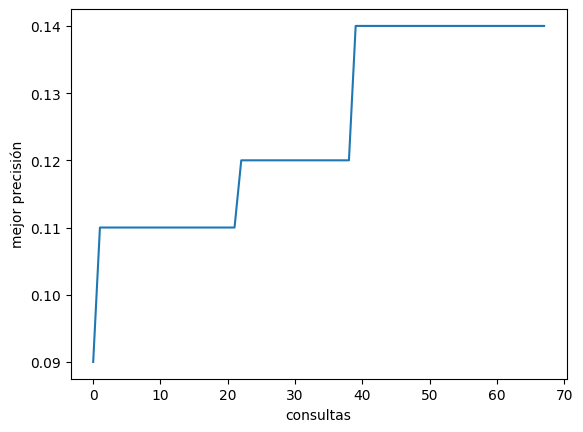

Evaluaciones: 68  |  consultas al modelo: 6800  |  fracción del espacio explorada: 0.069%
Tiempo total de GPU registrado: 0.0 min


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(REGISTRO)
pd.set_option("display.max_rows", 300)
display(df[["paso", "fase", "ranura_probada", *RANURAS, "temperatura", "precision", "segundos", "nota"]])

curva(historial)

evals = len(REGISTRO)
print(f"Evaluaciones: {evals}  |  consultas al modelo: {evals * len(INSTANCIAS)}  "
      f"|  fracción del espacio explorada: {evals / len(CONFIGS_T):.3%}")
print(f"Tiempo total de GPU registrado: {df['segundos'].sum() / 60:.1f} min")

### Precisión de cada opción por ranura (última vez que se probó)

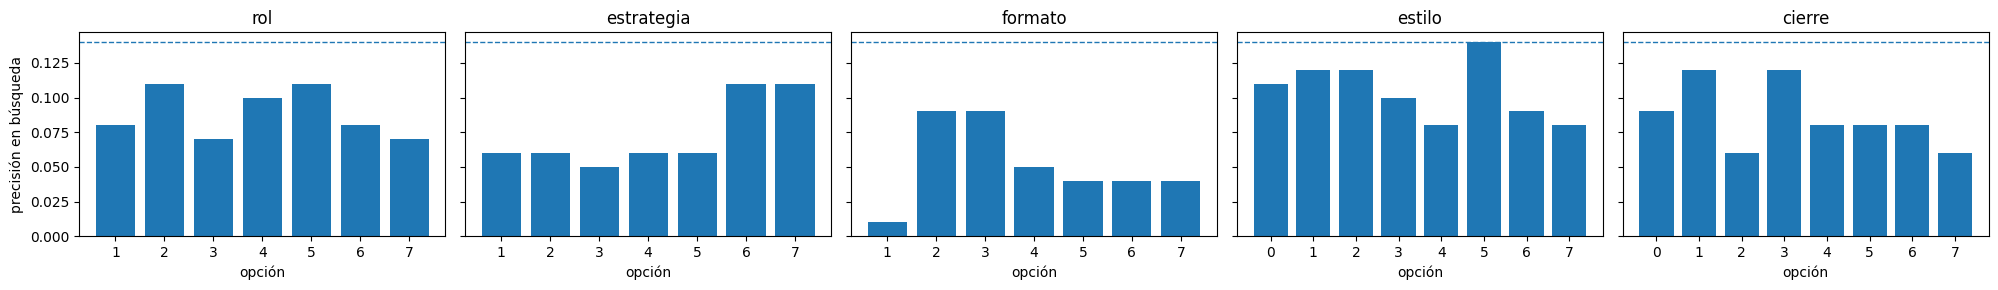

In [11]:
fig, ejes = plt.subplots(1, len(RANURAS), figsize=(4 * len(RANURAS), 3), sharey=True)
for eje, r in zip(ejes, RANURAS):
    sub = df[df["ranura_probada"] == r].groupby(r)["precision"].last()
    eje.bar(sub.index.astype(str), sub.values)
    eje.axhline(p_actual, ls="--", lw=1)
    eje.set_title(r); eje.set_xlabel("opción")
ejes[0].set_ylabel("precisión en búsqueda")
plt.tight_layout(); plt.show()

## 10 · Análisis de fallos: qué aportaron las trazas

- **Opciones descartadas por trazas** y el motivo: qué familia rompían. Estas opciones no se volvieron a evaluar en pasadas posteriores, lo que ahorró consultas.
- **Mapa observado ranura → familias**: qué familias cambiaron más al variar cada ranura, para contrastarlo con la hipótesis de la sección 6.
- **Fallos que persisten** en la configuración final.

In [12]:
print("Opciones descartadas por trazas:")
for r in RANURAS:
    for op, motivo in DESCARTADAS[r].items():
        print(f"  {r}={op}: {motivo}")
ahorro = sum(len(v) for v in DESCARTADAS.values())
print(f"Total descartadas: {ahorro} (cada una ahorra {len(INSTANCIAS)} consultas por pasada adicional)")

print("\nMapa observado (familias con mayor variación al cambiar cada ranura):")
for r in RANURAS:
    sub = df[df["ranura_probada"] == r]
    var = Counter()
    for fj in sub["fallos_por_familia"]:
        for f, n in json.loads(fj).items():
            var[f] = max(var[f], n)
    minimo = Counter()
    for f in var:
        minimo[f] = min(json.loads(fj).get(f, 0) for fj in sub["fallos_por_familia"])
    rango = {f: var[f] - minimo[f] for f in var}
    top = sorted(rango.items(), key=lambda x: -x[1])[:4]
    print(f"  {r:11s} hipótesis {HIPOTESIS[r]}  | observado {top}")

print("\nFallos que persisten en la configuración final:")
for fam, n in fallos_actual.most_common():
    print(f"  {fam:20s} {n}")

Opciones descartadas por trazas:
  rol=3: change_case +3
  rol=7: startend +3
  rol=1: paragraphs +3
  rol=2: paragraphs +3
  rol=4: detectable_format +3
  rol=5: detectable_format +3
  estrategia=4: detectable_format +3
  estrategia=1: paragraphs +4
  estrategia=2: detectable_format +3
  estrategia=3: detectable_format +5, startend +4
  estrategia=5: detectable_format +5
  estrategia=6: detectable_format +7
  formato=1: startend +4, change_case +3
  formato=4: detectable_format +3
  formato=5: punctuation +3
  formato=3: paragraphs +3
  formato=7: startend +3
  estilo=4: detectable_format +6
  estilo=6: paragraphs +3
  estilo=7: paragraphs +3
  estilo=2: change_case +3
  estilo=3: change_case +3
  estilo=1: detectable_format +3
  cierre=2: change_case +4, startend +3
  cierre=6: startend +3
  cierre=7: startend +3
  cierre=0: startend +3
  cierre=3: detectable_format +6
  cierre=4: last_word +3
Total descartadas: 29 (cada una ahorra 100 consultas por pasada adicional)

Mapa observado 

## 11 · Validación final con `oraculo.validar`

Las 87 instancias de validación **no se usaron** durante la búsqueda. Esta medición indica si la configuración generaliza a instancias nuevas del mismo tipo. No reemplaza la evaluación del profesor, que usa datos privados con familias de restricciones que no están en `datos_visibles.json`.

La validación **no se usa para elegir** otra configuración.

In [13]:
r_val = oraculo.validar(mejor[1], n=None)   # None = todas las instancias de validación
print("Configuración:", mejor[1])
print(f"Precisión en búsqueda:   {mejor[0]:.1%}")
print(f"Precisión en validación: {r_val.precision:.1%}")

validación: 10.3%  (87 inst)
    6  last_word:last_word_sent
    6  punctuation:punctuation_dot
    5  keywords:no_adjacent_consecutive
    5  copy:repeat_phrase
    5  combination:repeat_prompt
    4  first_word:first_word_sent
    4  letters:letter_counting
    3  punctuation:no_comma
Configuración: {'rol': 0, 'estrategia': 0, 'formato': 0, 'estilo': 5, 'cierre': 1, 'temperatura': 0.0}
Precisión en búsqueda:   14.0%
Precisión en validación: 10.3%


## 12 · Exportar `entrega.json`

In [ ]:
from google.colab import files
config_final = {k: mejor[1][k] for k in RANURAS}
config_final["temperatura"] = mejor[1].get("temperatura", 0.0)
entrega(grupo=GRUPO, config=config_final, semana=SEMANA)
files.download("entrega.json")
files.download(RUTA_REGISTRO)

{
 "grupo": "G01",
 "config": {
  "rol": 0,
  "estrategia": 0,
  "formato": 0,
  "estilo": 5,
  "cierre": 1,
  "temperatura": 0.0
 },
 "semana": 5
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>